In [1]:
import pandas as pd

# 3 QTRS plot data vs price airbnb Asheville 2024

In [3]:
# CSV file with hurricane mention from TPB 
triQ_df = pd.read_csv('Airbnb union of  3 QTRS.csv')


print(triQ_df.head())
triQ_df.shape

                                         Table Names  listing_id       date  \
0  Qtr_ending_Dec_w_listing_id_and_date.csv,Qtr_e...    15867765  4/21/2019   
1  Qtr_ending_Dec_w_listing_id_and_date.csv,Qtr_e...    15867765  4/24/2019   
2  Qtr_ending_Dec_w_listing_id_and_date.csv,Qtr_e...    15867765   5/1/2019   
3  Qtr_ending_Dec_w_listing_id_and_date.csv,Qtr_e...    15867765   5/5/2019   
4  Qtr_ending_Dec_w_listing_id_and_date.csv,Qtr_e...    15867765   5/8/2019   

         id  price  
0  15867765    109  
1  15867765    109  
2  15867765    109  
3  15867765    109  
4  15867765    109  


(918948, 5)

In [5]:
triQ_df['date'] = pd.to_datetime(triQ_df['date'], format='%m/%d/%Y')

In [6]:
print(triQ_df.head())
triQ_df.shape

                                         Table Names  listing_id       date  \
0  Qtr_ending_Dec_w_listing_id_and_date.csv,Qtr_e...    15867765 2019-04-21   
1  Qtr_ending_Dec_w_listing_id_and_date.csv,Qtr_e...    15867765 2019-04-24   
2  Qtr_ending_Dec_w_listing_id_and_date.csv,Qtr_e...    15867765 2019-05-01   
3  Qtr_ending_Dec_w_listing_id_and_date.csv,Qtr_e...    15867765 2019-05-05   
4  Qtr_ending_Dec_w_listing_id_and_date.csv,Qtr_e...    15867765 2019-05-08   

         id  price  
0  15867765    109  
1  15867765    109  
2  15867765    109  
3  15867765    109  
4  15867765    109  


(918948, 5)

In [28]:
triQ_df.columns

Index(['Table Names', 'listing_id', 'date', 'id', 'price'], dtype='object')

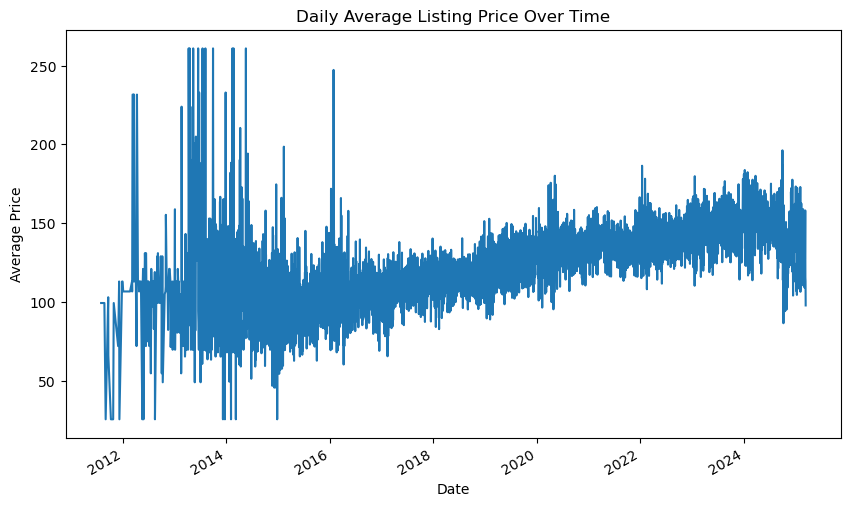

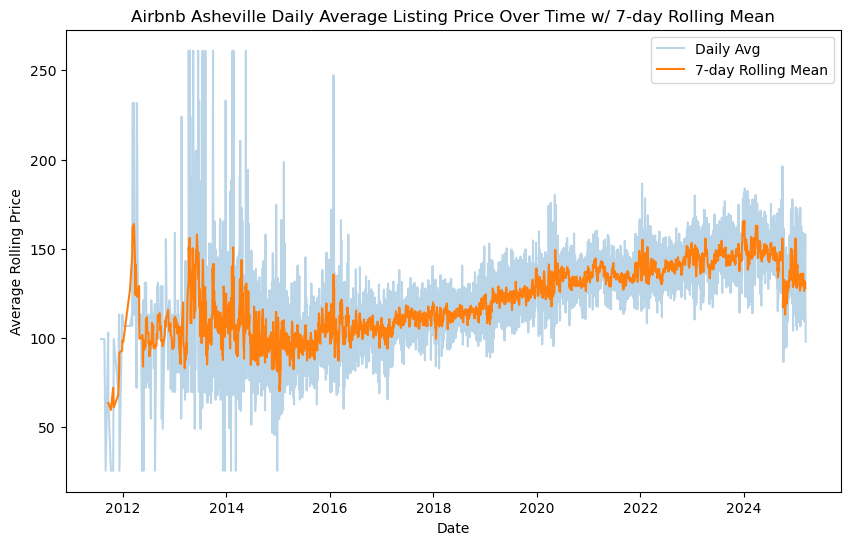

In [37]:
import matplotlib.pyplot as plt

# 1. Make sure 'date' is datetime and you have your df
triQ_df['date'] = pd.to_datetime(triQ_df['date'], format='%m/%d/%Y')

# 2. Compute the average price per date
daily_avg = triQ_df.groupby('date')['price'].mean()

# 3. Plot it as a line
plt.figure(figsize=(10, 6))
plt.plot(daily_avg.index, daily_avg.values)
plt.xlabel('Date')
plt.ylabel('Average Price')
plt.title('Daily Average Listing Price Over Time')
plt.gcf().autofmt_xdate()
plt.show()


rolling = daily_avg.rolling(window=7, center=True).mean()

plt.figure(figsize=(10, 6))
plt.plot(daily_avg.index, daily_avg, alpha=0.3, label='Daily Avg')
plt.xlabel('Date')
plt.ylabel('Average Rolling Price')
plt.title('Airbnb Asheville Daily Average Listing Price Over Time w/ 7-day Rolling Mean')
plt.plot(rolling.index, rolling,       label='7-day Rolling Mean')
plt.legend()
plt.show()


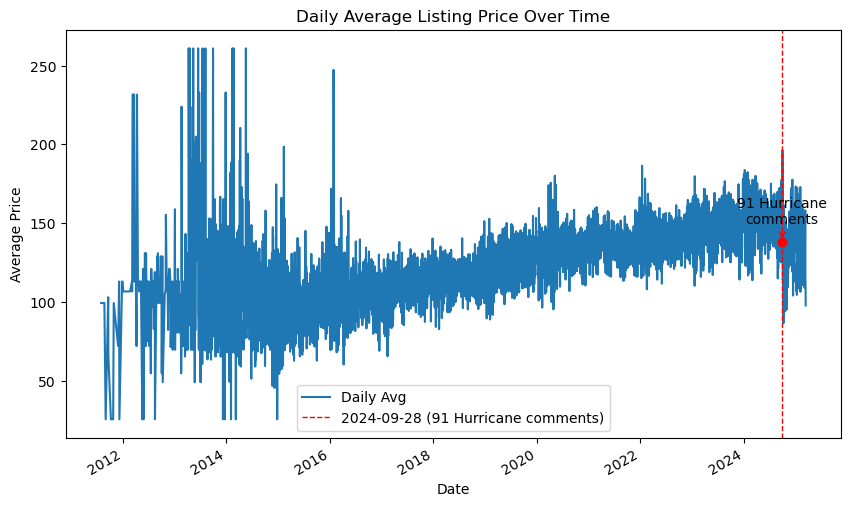

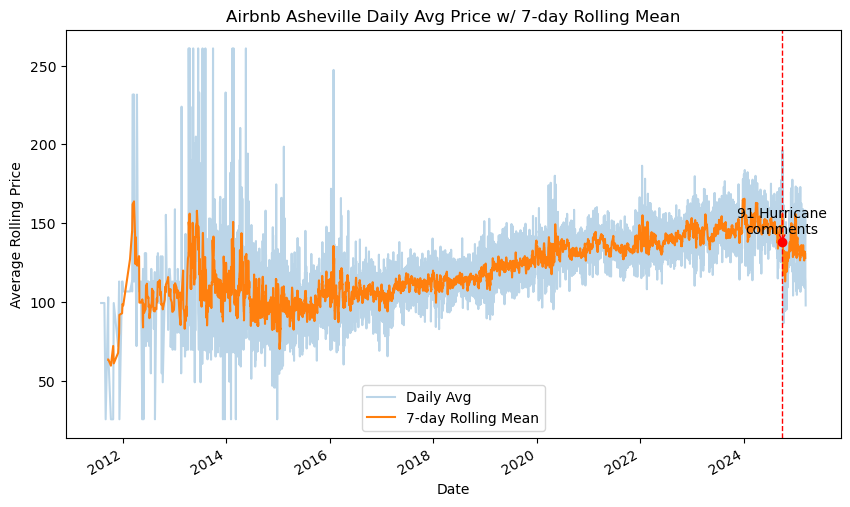

In [39]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Make sure 'date' is datetime and you have your df
triQ_df['date'] = pd.to_datetime(triQ_df['date'], format='%m/%d/%Y')

# 2. Compute the average price per date
daily_avg = triQ_df.groupby('date')['price'].mean()

# Identify your flag date and grab its price
flag_date = pd.to_datetime('2024-09-28')
flag_price = daily_avg.loc[flag_date]

# 3. Plot daily average
plt.figure(figsize=(10, 6))
plt.plot(daily_avg.index, daily_avg.values, label='Daily Avg')
plt.axvline(flag_date, color='red', linestyle='--', linewidth=1, label='2024-09-28 (91 Hurricane comments)')
plt.scatter([flag_date], [flag_price], color='red', zorder=5)
plt.annotate(
    '91 Hurricane\ncomments',
    xy=(flag_date, flag_price),
    xytext=(flag_date, flag_price + (daily_avg.max() - daily_avg.min())*0.05),
    ha='center',
    arrowprops=dict(arrowstyle='->', color='red')
)
plt.xlabel('Date')
plt.ylabel('Average Price')
plt.title('Daily Average Listing Price Over Time')
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

# 4. And on the rolling‐mean plot if desired
rolling = daily_avg.rolling(window=7, center=True).mean()

plt.figure(figsize=(10, 6))
plt.plot(daily_avg.index, daily_avg, alpha=0.3, label='Daily Avg')
plt.plot(rolling.index, rolling, label='7-day Rolling Mean')

# repeat the flag on this plot too
plt.axvline(flag_date, color='red', linestyle='--', linewidth=1)
plt.scatter([flag_date], [flag_price], color='red', zorder=5)
plt.annotate(
    '91 Hurricane\ncomments',
    xy=(flag_date, flag_price),
    xytext=(flag_date, flag_price + (rolling.max() - rolling.min())*0.05),
    ha='center',
    arrowprops=dict(arrowstyle='->', color='red')
)

plt.xlabel('Date')
plt.ylabel('Average Rolling Price')
plt.title('Airbnb Asheville Daily Avg Price w/ 7-day Rolling Mean')
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()


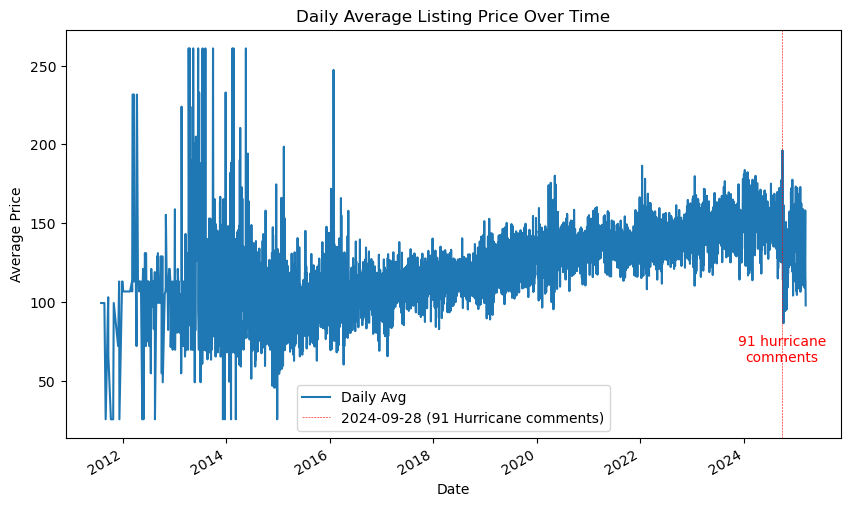

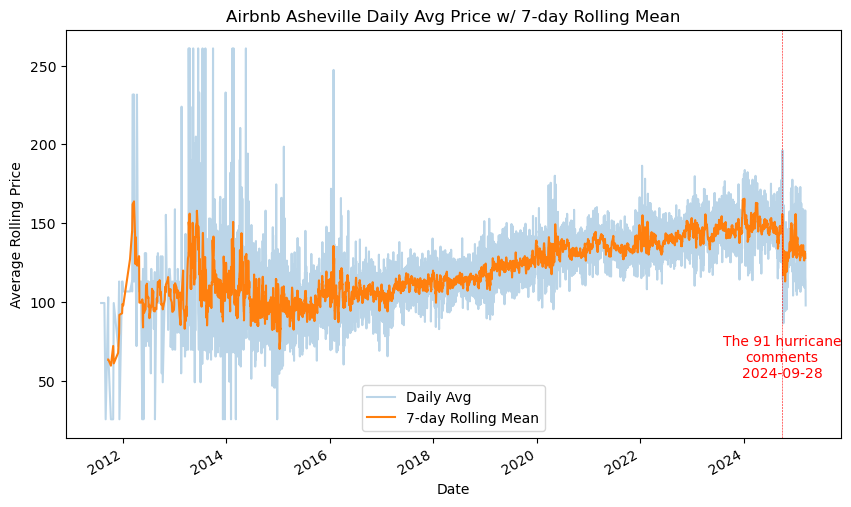

In [111]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Make sure 'date' is datetime and you have your df
triQ_df['date'] = pd.to_datetime(triQ_df['date'], format='%m/%d/%Y')

# 2. Compute the average price per date
daily_avg = triQ_df.groupby('date')['price'].mean()

# Identify your flag date and grab its price
flag_date = pd.to_datetime('2024-09-28')
flag_price = daily_avg.loc[flag_date]

# 3. Plot daily average
plt.figure(figsize=(10, 6))
plt.plot(daily_avg.index, daily_avg.values, label='Daily Avg')
plt.axvline(flag_date, color='red', linestyle='--', linewidth=0.4, label='2024-09-28 (91 Hurricane comments)')

# compute a downward offset (25% of the y‐range)
offset = (daily_avg.max() - daily_avg.min()) * 0.25
plt.annotate(
    '91 hurricane\ncomments',
    xy=(flag_date, flag_price),
    xytext=(flag_date, flag_price - offset),  # subtract to move down
    ha='center',
    va='top',  # align the top of the text box at the xytext point
    color='red'
)

plt.xlabel('Date')
plt.ylabel('Average Price')
plt.title('Daily Average Listing Price Over Time')
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

# 4. And on the rolling‐mean plot if desired
rolling = daily_avg.rolling(window=7, center=True).mean()

plt.figure(figsize=(10, 6))
plt.plot(daily_avg.index, daily_avg, alpha=0.3, label='Daily Avg')
plt.plot(rolling.index, rolling, label='7-day Rolling Mean')

# repeat the flag on this plot too
plt.axvline(flag_date, color='red', linestyle='--', linewidth=0.4)
# plt.scatter([flag_date], [flag_price], color='red')
# compute a downward offset (25% of the y‐range)
offset = (daily_avg.max() - daily_avg.min()) * 0.25

plt.annotate(
    'The 91 hurricane\ncomments\n2024-09-28',
    xy=(flag_date, flag_price),
    xytext=(flag_date, flag_price - offset),  # subtract to move down
    ha='center',
    va='top',  # align the top of the text box at the xytext point
    color='red'
)

plt.xlabel('Date')
plt.ylabel('Average Rolling Price')
plt.title('Airbnb Asheville Daily Avg Price w/ 7-day Rolling Mean')
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()


## Zoom in

In [11]:
zoom_triQ_df  = triQ_df[(triQ_df ['date'] >= '2024-01-01') & (triQ_df['date'] <= '2024-12-30')]

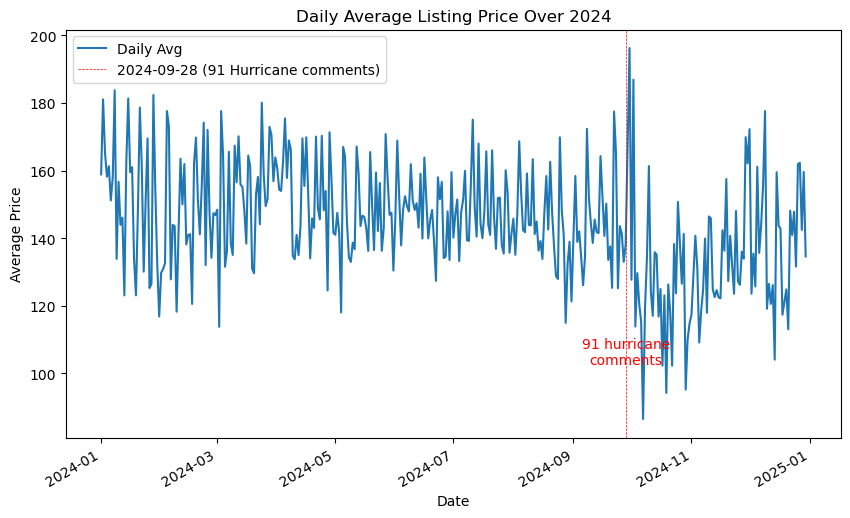

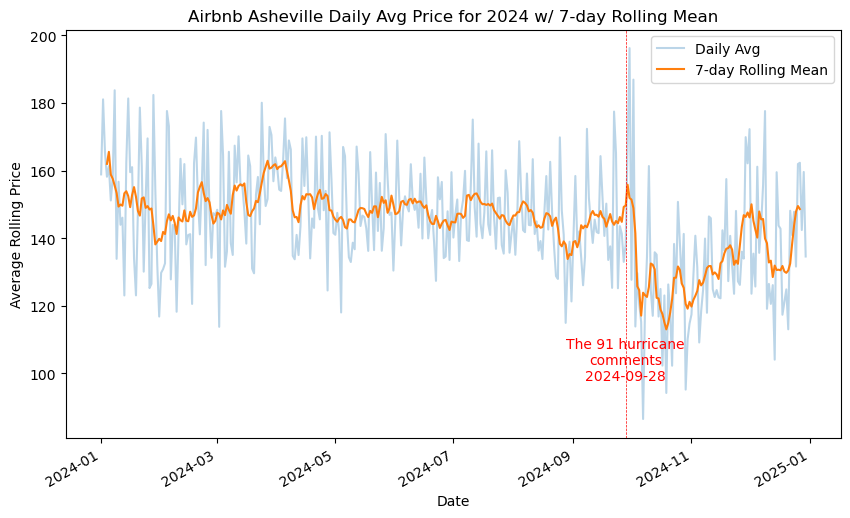

In [113]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Make sure 'date' is datetime and you have your df
# zoom_triQ_df['date'] = pd.to_datetime(zoom_triQ_df['date'], format='%m/%d/%Y')

# 2. Compute the average price per date
daily_avg = zoom_triQ_df.groupby('date')['price'].mean()

# Identify your flag date and grab its price
flag_date = pd.to_datetime('2024-09-28')
flag_price = daily_avg.loc[flag_date]

# 3. Plot daily average
plt.figure(figsize=(10, 6))
plt.plot(daily_avg.index, daily_avg.values, label='Daily Avg')
plt.axvline(flag_date, color='red', linestyle='--', linewidth=0.5, label='2024-09-28 (91 Hurricane comments)')

# compute a downward offset (25% of the y‐range)
offset = (daily_avg.max() - daily_avg.min()) * 0.25
plt.annotate(
    '91 hurricane\ncomments',
    xy=(flag_date, flag_price),
    xytext=(flag_date, flag_price - offset),  # subtract to move down
    ha='center',
    va='top',  # align the top of the text box at the xytext point
    color='red'
)

plt.xlabel('Date')
plt.ylabel('Average Price')
plt.title('Daily Average Listing Price Over 2024')
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()

# 4. And on the rolling‐mean plot if desired
rolling = daily_avg.rolling(window=7, center=True).mean()

plt.figure(figsize=(10, 6))
plt.plot(daily_avg.index, daily_avg, alpha=0.3, label='Daily Avg')
plt.plot(rolling.index, rolling, label='7-day Rolling Mean')

# repeat the flag on this plot too
plt.axvline(flag_date, color='red', linestyle='--', linewidth=0.5)
# plt.scatter([flag_date], [flag_price], color='red')
# compute a downward offset (25% of the y‐range)
offset = (daily_avg.max() - daily_avg.min()) * 0.25

plt.annotate(
    'The 91 hurricane\ncomments\n2024-09-28',
    xy=(flag_date, flag_price),
    xytext=(flag_date, flag_price - offset),  # subtract to move down
    ha='center',
    va='top',  # align the top of the text box at the xytext point
    color='red'
)

plt.xlabel('Date')
plt.ylabel('Average Rolling Price')
plt.title('Airbnb Asheville Daily Avg Price for 2024 w/ 7-day Rolling Mean')
plt.legend()
plt.gcf().autofmt_xdate()
plt.show()


In [13]:
# Save the zoom_triQ_df DataFrame to a CSV file
zoom_triQ_df.to_csv('zoom_triQ_df.csv', index=False)
print("zoom_triQ_df saved to 'zoom_triQ_df.csv'")


zoom_triQ_df saved to 'zoom_triQ_df.csv'
